This notebook reproduces Fig. 10. We compute the runtime for obtaining the pulses when solving the $(\alpha, \beta)$ hypergeometries for different models. For all cases, we average the calculation over several runs, mitigating the fluctuations in the CPU times.

First, we solve the Landau-Zener problem for several pairs of $(\alpha, \beta)$, with $z(t=0)=-z(t=t_\mathrm{f})=-10\,x$. In this case, the instantaneous eigenstates are computed beforehand, and the runtime includes the calculation of $\mathcal{G}^{(\alpha,\beta)}$ and the solution of the ODE.

Second, we solve a periodic Landau-Zener model, given by the Hamiltonian
$$
\hat{H}_{pLZ}=\cos z(t) \,\hat{\sigma}_z + x \,\hat{\sigma}_x,
$$
with $\alpha=\beta=2$. In this case, we compute the runtime versus the number of anticrossings encountered during the transfer (again, excluding the diagonalization).

Finally, we solve an all-to-all model, where all the states are coupled to each other. The Hamiltonian describing this model reads
$$
\hat{H}_N = \sum_{k=0}^{N-1} \left[(-1)^kz(t)+k\Delta\right]\hat{n}_k + x\sum_{k<k'}(\hat{c}_k^\dagger \hat{c}_{k'} + \hat{c}_{k'}^\dagger \hat{c}_k).
$$
The parameters $x,\Delta$ control the size and the position of the anticrossings, $z(t)$ is our control field, $\hat{c}_k,\hat{c}_k^\dagger$ are the annihilation and creation operators, respectively, and $\hat{n}_k=\hat{c}_k^\dagger\hat{c}_k$ is the number operator. We compute the adiabatic transfer following the instantaneous eigenstate located in the middle of the band structure, with $\Delta=5x$, $z(t=0) = -N(x + \Delta / 3)$, $z(t=t_\mathrm{f}) = N(x + \Delta / 3)+\Delta/3$, and $\alpha=\beta=2$. In this case, we only obtain a total of $k_\mathrm{max}$ eigenstates, centered in the eigenstate of interest, using a sparse diagonalization, which is included in the runtime.

Note that the absolute runtimes depend on the CPU and on the resolution of the grids, which is lower here than in the manuscript (see the comments in the code).

In [1]:
from time import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from scipy.sparse.linalg import eigsh
from tqdm.auto import tqdm

from HQUAD_lib.plotting_utils import add_labels, extract_color_map
from HQUAD_lib.QUAD_utils import compute_x_quad

In [2]:
n_runs = 3  # Increase to get more stable results (20 runs in the manuscript)


def average_run_time(fun, *params) -> float:
    """Average over n_runs of the runtime (in seconds) returned by fun(*params)"""
    return float(np.average([fun(*params) for _ in range(n_runs)]))

# Landau-Zener problem versus $(\alpha, \beta)$

In [3]:
x = 1

n_s = 2**18 + 1  # In the manuscript, 2 ** 20 + 1 points are used
zs = np.linspace(-10, 10, n_s)
partial_hamiltonian_LZ = np.array([[[1, 0], [0, -1]] for _ in zs])

hypermatrix = np.array([[[z, x], [x, -z]] for z in zs])
eigvalues_LZ, eigmodes_LZ = np.linalg.eigh(hypermatrix)


def run_time_LZ(alpha: float, beta: float) -> float:
    t0 = time()
    compute_x_quad(
        eigvalues_LZ,
        eigmodes_LZ,
        zs,
        partial_hamiltonian_LZ,
        adiabatic_state=0,
        alpha=alpha,
        beta=beta,
        n_s=n_s,
        limit_sup=np.inf,
        limit_inf=0,
    )
    return time() - t0


alphas = np.linspace(-10, 10, 11)  # Increase number of samples to enhance resolution
betas = alphas

pbar = tqdm(total=len(alphas) * len(betas))
times_ab = np.zeros((len(alphas), len(betas)))
for i in range(len(alphas)):
    for j in range(len(betas)):
        times_ab[i, j] = average_run_time(run_time_LZ, alphas[i], betas[j])
        pbar.update()
pbar.close()

  0%|          | 0/121 [00:00<?, ?it/s]

# Periodic Landau-Zener problem versus the number of anticrossings

In [4]:
x_periodic = 0.1
n_s_periodic = 2**15 + 1  # In the manuscript, 2 ** 18 + 1 points are used


def run_time_periodic(n_anticrossings: int) -> float:
    # The anticrossings are located at z = pi / 2 + k pi
    zs = np.linspace(0, 1, n_s_periodic) * np.pi * n_anticrossings
    partial_hamiltonian = np.array([[[-np.sin(z), 0], [0, np.sin(z)]] for z in zs])

    hypermatrix = np.array(
        [[[np.cos(z), x_periodic], [x_periodic, -np.cos(z)]] for z in zs]
    )
    eigvalues, eigmodes = np.linalg.eigh(hypermatrix)

    t0 = time()
    compute_x_quad(
        eigvalues,
        eigmodes,
        zs,
        partial_hamiltonian,
        adiabatic_state=0,
        alpha=2,
        beta=2,
        n_s=2**15 + 1,  # n_s = 2 ** 20 + 1 in the manuscript
        limit_inf=1e-8,
        limit_sup=1e8,
    )
    return time() - t0


n_anticrossings = np.arange(1, 100)
times_periodic = np.array(
    [average_run_time(run_time_periodic, n) for n in tqdm(n_anticrossings)]
)

  0%|          | 0/99 [00:00<?, ?it/s]

In [5]:
def line(x: np.ndarray, a0: float, a1: float) -> np.ndarray:
    return a0 + a1 * x


popt, _ = curve_fit(line, n_anticrossings, times_periodic)
print(f"Run time = {popt[0]:.2f} + {popt[1]:.3f} (#anticrossings) s")

Run time = 0.04 + 0.011 (#anticrossings) s


# All-to-all model versus the number of states

In [6]:
def hamiltonian_all_to_all(z: float, Delta: float, x: float, N: int) -> np.ndarray:
    diagonal = np.array([z * (-1) ** k + Delta * k for k in range(N)], dtype=float)
    return np.diag(diagonal) + (np.ones((N, N)) - np.eye(N)) * x


x_a2a = 1
Delta = 5

Ns = np.arange(4, 10)  # Increase to get results for larger systems


def run_time_all_to_all(N: int, k: int) -> float:
    E_0 = Delta * N / 2  # Energy in the middle of the spectrum
    zs = np.linspace(
        -N * (x_a2a + Delta / 3), N * (x_a2a + Delta / 3) + Delta / 3, 2**12 + 1
    )

    partial_hamiltonian = np.array([hamiltonian_all_to_all(1, 0, 0, N) for _ in zs])
    hypermatrix = np.array([hamiltonian_all_to_all(z, Delta, x_a2a, N) for z in zs])

    t0 = time()

    # Sparse diagonalization, obtaining only k states around E_0
    eigvalues, eigmodes = zip(*[eigsh(H, sigma=E_0, k=k) for H in hypermatrix])

    compute_x_quad(
        np.array(eigvalues),
        np.array(eigmodes),
        zs,
        partial_hamiltonian,
        adiabatic_state=k // 2,
        alpha=2,
        beta=2,
    )
    return time() - t0


times_a2a = [
    [
        average_run_time(run_time_all_to_all, N, k)
        for k in tqdm(range(2, N), leave=False)
    ]
    for N in tqdm(Ns, desc="Run in N")
]

Run in N:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

# Plot

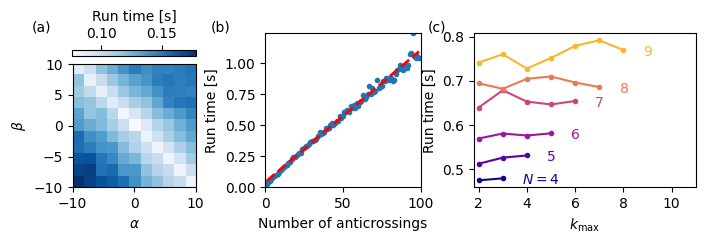

In [7]:
fig, axs = plt.subplot_mosaic("ABC", figsize=(8.25, 2), width_ratios=[0.7, 0.7, 1])
ax_ab, ax_periodic, ax_a2a = axs["A"], axs["B"], axs["C"]

# (a) Versus alpha and beta
im = ax_ab.imshow(
    times_ab.T,
    origin="lower",
    cmap="Blues",
    extent=(min(alphas), max(alphas), min(betas), max(betas)),
)

plt.colorbar(im, ax=ax_ab, label="Run time [s]", location="top", shrink=0.8)
ax_ab.set_xlabel(r"$\alpha$")
ax_ab.set_ylabel(r"$\beta$")

# (b) Versus the number of anticrossings
ax_periodic.plot(n_anticrossings, times_periodic, ".", label="Numeric")
ax_periodic.plot(
    n_anticrossings, line(n_anticrossings, *popt), "r--", label="Fit", lw=2
)

ax_periodic.set_xlabel("Number of anticrossings")
ax_periodic.set_ylabel("Run time [s]")
ax_periodic.set_ylim(0, max(times_periodic))
ax_periodic.set_xlim(0, max(n_anticrossings) + 1)

# (c) Versus the number of states
colors = extract_color_map(len(Ns) + 1, cmap="plasma")

for i, (N, times_N) in enumerate(zip(Ns, times_a2a)):
    ks = np.arange(len(times_N)) + 2
    ax_a2a.plot(ks, times_N, marker=".", color=colors[i])
    ax_a2a.text(
        ks[-1] + 0.8,
        times_N[-1],
        f"$N={N}$" if i == 0 else f"${N}$",
        va="center_baseline",
        ha="left",
        color=colors[i],
    )

ax_a2a.set_xlim(1.8, max(Ns) + 2)
ax_a2a.set_xlabel(r"$k_\mathrm{max}$")
ax_a2a.set_ylabel("Run time [s]")

fig.subplots_adjust(wspace=0.3)
add_labels([ax_ab] * 3, [[-0.25, 1.3], [1.2, 1.3], [2.96, 1.3]])